# 02 · Modelling — SPY Buy / Hold / Sell Classifier

This notebook is the core of the project. It follows the protocol fixed **before** training (see `docs/` plan §3):

| Step | Data used | Decides |
|---|---|---|
| Hyper-parameter search | **Train 2010–2020**, `TimeSeriesSplit(n_splits=5, gap=5)` | parameters of each candidate (score: macro-F1) |
| Model & variant selection | **Validation 2021–2022** | final model (rule: highest validation macro-F1) |
| Signal-rule selection | **Validation-period backtest** (model trained on Train only) | probability margin / minimum holding (rule: highest after-cost Sharpe, ties → fewer trades) |
| Final refit | Train + Val 2010–2022 | — |
| **Final evaluation (once)** | **Test 2023–2024** — opened only in §9 after the configuration is frozen (Gate G4) | nothing |

Every split boundary drops the last 5 rows of the earlier segment so that no 5-day label window crosses into a later segment. All scaling/resampling happens inside sklearn Pipelines, re-fit on each training fold.

In [1]:
import sys, json, warnings
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))
warnings.filterwarnings("ignore", category=FutureWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from sklearn.base import clone
from sklearn.model_selection import cross_val_score
from sklearn.inspection import permutation_importance

from src import config
from src.data import load_snapshot
from src.dataset import build_dataset
from src.features import FEATURE_COLS, COMPACT_COLS
from src.labels import quantile_thresholds, vol_scaled_thresholds, to_class
from src.split import get_segments, make_cv, train_val_combined
from src.models import baselines, make_pipeline, tune
from src.evaluate import classification_metrics, per_year_macro_f1, plot_confusion, log_experiment
from src.backtest import apply_rule, to_positions, run_backtest, summarize

sns.set_theme(style="whitegrid")
pd.set_option("display.float_format", "{:.4f}".format)
np.random.seed(config.SEED)
def savefig(name): plt.savefig(config.FIG_DIR / f"model_{name}.png", dpi=120, bbox_inches="tight")

## 1. Data, segments and validation protocol

In [2]:
raw = load_snapshot()
prices = raw[["Open", "Close"]]
ds = build_dataset(raw)
segs = get_segments(ds)                       # test is NOT loaded here
train, val = segs["train"], segs["val"]
Xtr, ytr = train[FEATURE_COLS], train["label"].astype(int)
Xva, yva = val[FEATURE_COLS], val["label"].astype(int)
val_days = ds.loc[config.VAL[0]:config.VAL[1]]   # every validation day (features only) for the backtest
cv = make_cv()

LOG = config.OUTPUT_DIR / "experiment_log.csv"
LOG.unlink(missing_ok=True)                   # the log is regenerated by this notebook
print(f"train {len(train)} rows {train.index.min().date()}→{train.index.max().date()}")
print(f"val   {len(val)} rows {val.index.min().date()}→{val.index.max().date()}")
for i, (a, b) in enumerate(cv.split(Xtr)):
    print(f"CV fold {i}: train ≤ {Xtr.index[a[-1]].date()}  |  validate {Xtr.index[b[0]].date()} → {Xtr.index[b[-1]].date()}")

train 2764 rows 2010-01-04→2020-12-23
val   498 rows 2021-01-04→2022-12-22
CV fold 0: train ≤ 2011-10-26  |  validate 2011-11-03 → 2013-09-04
CV fold 1: train ≤ 2013-08-27  |  validate 2013-09-05 → 2015-07-02
CV fold 2: train ≤ 2015-06-25  |  validate 2015-07-06 → 2017-05-01
CV fold 3: train ≤ 2017-04-24  |  validate 2017-05-02 → 2019-02-28
CV fold 4: train ≤ 2019-02-21  |  validate 2019-03-01 → 2020-12-23


## 2. Experiment helpers
`record()` scores a fitted estimator on validation (classification metrics **and** a long-only after-cost backtest using the argmax signal) and appends one row to `outputs/experiment_log.csv`. Test data never passes through this function.

In [3]:
RESULTS, MODELS = {}, {}

def predict_actions(est, cols, days=val_days, margin=None):
    X = days[cols]
    if hasattr(est, "predict_proba"):
        proba = pd.DataFrame(est.predict_proba(X), index=X.index, columns=est.classes_)
        return apply_rule(proba, margin)
    return pd.Series(est.predict(X), index=X.index)

def val_backtest(est, cols, margin=None, min_hold=0):
    pf = run_backtest(to_positions(predict_actions(est, cols, margin=margin), min_hold=min_hold), prices)
    return summarize(pf)

def record(exp_id, name, est, cols, cv_mean, cv_std, y_val=yva, X_val=None,
           label_scheme="±1% close→close 5d", feature_set="all (15)", imbalance="class_weight=balanced", params=""):
    X_val = Xva[cols] if X_val is None else X_val[cols]
    pred = est.predict(X_val)
    proba = est.predict_proba(X_val) if hasattr(est, "predict_proba") else None
    m = classification_metrics(y_val, pred, proba)
    bt = val_backtest(est, cols)
    RESULTS[exp_id] = {"name": name, "label_scheme": label_scheme, "feature_set": feature_set,
                       "imbalance": imbalance, "cv_macro_f1": cv_mean, "cv_std": cv_std, **m,
                       "val_bt_sharpe": bt["sharpe"], "val_bt_return": bt["total_return"], "val_bt_trades": bt["n_trades"]}
    MODELS[exp_id] = (est, cols)
    log_experiment({"exp_id": exp_id, "split": "train 2010-20 / val 2021-22, gap 5",
                    "label_scheme": label_scheme, "feature_set": feature_set, "imbalance": imbalance,
                    "model": name, "params": params, "cv_macro_f1_mean": round(cv_mean, 4) if cv_mean == cv_mean else "",
                    "cv_macro_f1_std": round(cv_std, 4) if cv_std == cv_std else "",
                    "val_macro_f1": m["macro_f1"], "val_accuracy": m["accuracy"], "val_bt_sharpe": bt["sharpe"]})
    return m

def show(ids=None):
    cols = ["name", "label_scheme", "feature_set", "imbalance", "cv_macro_f1", "cv_std", "macro_f1",
            "accuracy", "balanced_accuracy", "f1_Sell", "f1_Hold", "f1_Buy", "val_bt_sharpe", "val_bt_trades"]
    df = pd.DataFrame(RESULTS).T[cols]
    return df.loc[ids] if ids else df

## 3. Baselines (E00–E03)
B0 majority class, B1 stratified random guess, B2 always-Buy (= stay invested), B3 a simple momentum rule (`ret_20` and `Close` vs `SMA200`). Every model must beat these to be worth anything.

In [4]:
for i, (name, est) in enumerate(baselines().items()):
    s = cross_val_score(est, Xtr, ytr, cv=cv, scoring="f1_macro")
    est.fit(Xtr, ytr)
    record(f"E{i:02d}", name, est, FEATURE_COLS, s.mean(), s.std(), imbalance="n/a")
show()

,name,label_scheme,feature_set,imbalance,cv_macro_f1,cv_std,macro_f1,accuracy,balanced_accuracy,f1_Sell,f1_Hold,f1_Buy,val_bt_sharpe,val_bt_trades
E00,B0_majority,±1% close→close 5d,all (15),n/a,0.2052,0.0262,0.1704,0.3434,0.3333,0.0000,0.5112,0.0000,0.0000,0
E01,B1_stratified,±1% close→close 5d,all (15),n/a,0.3141,0.0134,0.3328,0.3434,0.3374,0.2433,0.3970,0.3582,-0.4720,66
E02,B2_always_buy,±1% close→close 5d,all (15),n/a,0.1700,0.0191,0.1784,0.3655,0.3333,0.0000,0.0000,0.5353,0.2670,1
E03,B3_momentum_rule,±1% close→close 5d,all (15),n/a,0.2569,0.0430,0.3051,0.3072,0.3072,0.3676,0.2006,0.3470,0.1020,5


## 4. Candidate models (E04–E08)
Each candidate is tuned with `RandomizedSearchCV` over the full Pipeline using time-series CV (macro-F1). Order follows the brief: interpretable linear model first, then trees.

In [5]:
SEARCHES = {}
def run_search(exp_id, name, n_iter, cols=FEATURE_COLS, feature_set="all (15)", **kw):
    s = tune(name, Xtr[cols], ytr, cv, n_iter=n_iter, **kw)
    SEARCHES[exp_id] = s
    i = s.best_index_
    imb = "SMOTE (in-fold)" if kw.get("smote") else ("none" if kw.get("class_weight", "balanced") is None else "class_weight=balanced")
    params = {k.replace("clf__", ""): (round(v, 4) if isinstance(v, float) else v) for k, v in s.best_params_.items()}
    record(exp_id, name + (" +SMOTE" if kw.get("smote") else ""), s.best_estimator_, cols,
           s.cv_results_["mean_test_score"][i], s.cv_results_["std_test_score"][i],
           feature_set=feature_set, imbalance=imb, params=json.dumps(params))
    print(exp_id, name, imb, feature_set, "best params:", params,
          f"| CV macro-F1 {s.best_score_:.4f}  (train-fold {s.cv_results_['mean_train_score'][i]:.4f})")

run_search("E04", "LR", n_iter=20)                              # M1 logistic regression, balanced
run_search("E05", "LR", n_iter=20, class_weight=None)          # M1 without class weighting (imbalance ablation)
run_search("E06", "RF", n_iter=20)                              # M2 random forest
run_search("E07", "HGB", n_iter=25)                             # M3 hist gradient boosting
run_search("E08", "LR", n_iter=20, class_weight=None, smote=True)  # optional SMOTE inside folds
show()

E04 LR class_weight=balanced all (15) best params: {'C': np.float64(0.0012)} | CV macro-F1 0.4080  (train-fold 0.4411)
E05 LR none all (15) best params: {'C': np.float64(0.0165)} | CV macro-F1 0.3851  (train-fold 0.4179)


E06 RF class_weight=balanced all (15) best params: {'max_depth': None, 'max_features': 'sqrt', 'min_samples_leaf': 68} | CV macro-F1 0.4033  (train-fold 0.5422)


E07 HGB class_weight=balanced all (15) best params: {'l2_regularization': np.float64(0.9219), 'learning_rate': np.float64(0.013), 'max_depth': 4, 'max_iter': 301, 'min_samples_leaf': 59} | CV macro-F1 0.3992  (train-fold 0.7437)


E08 LR SMOTE (in-fold) all (15) best params: {'C': np.float64(0.0012)} | CV macro-F1 0.4082  (train-fold 0.4435)


,name,label_scheme,feature_set,imbalance,cv_macro_f1,cv_std,macro_f1,accuracy,balanced_accuracy,f1_Sell,f1_Hold,f1_Buy,val_bt_sharpe,val_bt_trades
E00,B0_majority,±1% close→close 5d,all (15),n/a,0.2052,0.0262,0.1704,0.3434,0.3333,0.0000,0.5112,0.0000,0.0000,0
E01,B1_stratified,±1% close→close 5d,all (15),n/a,0.3141,0.0134,0.3328,0.3434,0.3374,0.2433,0.3970,0.3582,-0.4720,66
E02,B2_always_buy,±1% close→close 5d,all (15),n/a,0.1700,0.0191,0.1784,0.3655,0.3333,0.0000,0.0000,0.5353,0.2670,1
E03,B3_momentum_rule,±1% close→close 5d,all (15),n/a,0.2569,0.0430,0.3051,0.3072,0.3072,0.3676,0.2006,0.3470,0.1020,5
E04,LR,±1% close→close 5d,all (15),class_weight=balanced,0.4080,0.0420,0.3593,0.3815,0.3682,0.1811,0.4800,0.4169,-0.1760,16
E05,LR,±1% close→close 5d,all (15),none,0.3851,0.0214,0.3289,0.4157,0.3907,0.0134,0.4896,0.4838,0.1910,4
E06,RF,±1% close→close 5d,all (15),class_weight=balanced,0.4033,0.0188,0.4036,0.4016,0.4011,0.3473,0.4530,0.4107,-0.0550,41
E07,HGB,±1% close→close 5d,all (15),class_weight=balanced,0.3992,0.0198,0.3220,0.3293,0.3232,0.2382,0.3258,0.4019,-0.3740,34
E08,LR +SMOTE,±1% close→close 5d,all (15),SMOTE (in-fold),0.4082,0.0426,0.3640,0.3855,0.3722,0.1878,0.4784,0.4257,-0.2680,13


**Reading (CV = Train folds, Val = 2021–2022).**
- Every tuned model beats every baseline in CV (macro-F1 ≈ 0.39–0.41 vs ≤ 0.31). On validation the spread is wider: **RF 0.404**, the LR family ≈ 0.36, HGB 0.32.
- **Boosting overfits.** HGB scores 0.74 macro-F1 on its training folds but 0.40 in CV, and drops to 0.32 on validation. RF shows a smaller gap (0.54 → 0.40) and holds up on validation.
- **Class weighting matters.** Without weights (E05) LR almost never predicts Sell (val F1_Sell = 0.01). Its *accuracy* is the best of all (0.416), yet macro-F1 is worse: the classic imbalance trap. In-fold SMOTE (E08) behaves almost exactly like `class_weight="balanced"` (0.364 vs 0.359), so it adds complexity without benefit.
- Fold-to-fold std is 0.02–0.04, which is as large as most differences between LR variants. Those differences are not meaningful.

## 5. Feature-set ablation (E09–E10)
EDA showed heavy redundancy between indicators. The compact set keeps one representative per family: `ret_1, ret_20, close_sma200, rsi_14, macd_hist, bb_width, vol_20, vol_z20`.

In [6]:
run_search("E09", "LR", n_iter=20, cols=COMPACT_COLS, feature_set="compact (8)")
run_search("E10", "HGB", n_iter=25, cols=COMPACT_COLS, feature_set="compact (8)")
show(["E04", "E09", "E07", "E10"])

E09 LR class_weight=balanced compact (8) best params: {'C': np.float64(0.0042)} | CV macro-F1 0.4142  (train-fold 0.4463)


E10 HGB class_weight=balanced compact (8) best params: {'l2_regularization': np.float64(0.8022), 'learning_rate': np.float64(0.0125), 'max_depth': 4, 'max_iter': 58, 'min_samples_leaf': 107} | CV macro-F1 0.3970  (train-fold 0.5267)


,name,label_scheme,feature_set,imbalance,cv_macro_f1,cv_std,macro_f1,accuracy,balanced_accuracy,f1_Sell,f1_Hold,f1_Buy,val_bt_sharpe,val_bt_trades
E04,LR,±1% close→close 5d,all (15),class_weight=balanced,0.4080,0.0420,0.3593,0.3815,0.3682,0.1811,0.4800,0.4169,-0.1760,16
E09,LR,±1% close→close 5d,compact (8),class_weight=balanced,0.4142,0.0444,0.3619,0.3775,0.3653,0.2000,0.4644,0.4213,-0.2790,8
E07,HGB,±1% close→close 5d,all (15),class_weight=balanced,0.3992,0.0198,0.3220,0.3293,0.3232,0.2382,0.3258,0.4019,-0.3740,34
E10,HGB,±1% close→close 5d,compact (8),class_weight=balanced,0.3970,0.0297,0.2915,0.3072,0.3033,0.2396,0.2262,0.4087,-0.2720,23


## 6. Label-definition sensitivity (E11–E13)
These change the **target itself**, so their macro-F1 is *not* comparable with E04–E10 (a different question is being answered). They are compared on the validation backtest only and are reported as a sensitivity analysis — the primary label stays the brief's ±1% close-to-close definition.
- **E11 quantile thresholds**: 33rd/67th percentiles of *training* `r_fwd` (≈ balanced classes).
- **E12 volatility-scaled**: ±0.5·σ₂₀(t)·√5.
- **E13 execution-aligned**: Open(t+6)/Open(t+1) − 1 with ±1%.

In [7]:
def label_variant(exp_id, ds_v, scheme):
    sv = get_segments(ds_v)
    tr_v, va_v = sv["train"], sv["val"]
    s = tune("LR", tr_v[FEATURE_COLS], tr_v["label"].astype(int), cv, n_iter=20)
    i = s.best_index_
    record(exp_id, "LR", s.best_estimator_, FEATURE_COLS, s.cv_results_["mean_test_score"][i],
           s.cv_results_["std_test_score"][i], y_val=va_v["label"].astype(int), X_val=va_v,
           label_scheme=scheme, params=json.dumps({"C": round(s.best_params_["clf__C"], 4)}))
    return va_v["label"].value_counts(normalize=True).rename(config.CLASS_NAMES)

hi, lo = quantile_thresholds(train["r_fwd"])
ds_q = ds.copy(); ds_q["label"] = to_class(ds["r_fwd"], hi, lo)
band, nband = vol_scaled_thresholds(ds["vol_20"])
ds_v = ds.copy(); ds_v["label"] = to_class(ds["r_fwd"], band, nband)
ds_o = build_dataset(raw, label_kind="open")
print(f"quantile thresholds from training: Buy > {hi:.4%}, Sell < {lo:.4%}")
bal = pd.DataFrame({"E11 quantile": label_variant("E11", ds_q, f"quantile ({lo:.2%}, {hi:.2%})"),
                    "E12 vol-scaled": label_variant("E12", ds_v, "±0.5·σ20·√5"),
                    "E13 open→open": label_variant("E13", ds_o, "±1% open→open 5d")})
display(bal.round(3).rename_axis("val class share"))
show(["E04", "E11", "E12", "E13"])

quantile thresholds from training: Buy > 1.0965%, Sell < -0.2076%


,E11 quantile,E12 vol-scaled,E13 open→open
val class share,,,
Buy,0.3530,0.3550,0.3430
Hold,0.2470,0.3670,0.3410
Sell,0.4000,0.2770,0.3150


,name,label_scheme,feature_set,imbalance,cv_macro_f1,cv_std,macro_f1,accuracy,balanced_accuracy,f1_Sell,f1_Hold,f1_Buy,val_bt_sharpe,val_bt_trades
E04,LR,±1% close→close 5d,all (15),class_weight=balanced,0.4080,0.0420,0.3593,0.3815,0.3682,0.1811,0.4800,0.4169,-0.1760,16
E11,LR,"quantile (-0.21%, 1.10%)",all (15),class_weight=balanced,0.3895,0.0139,0.3596,0.3655,0.3799,0.2357,0.4061,0.4371,-0.0450,12
E12,LR,±0.5·σ20·√5,all (15),class_weight=balanced,0.3809,0.0369,0.3220,0.3233,0.3262,0.2939,0.3930,0.2792,-0.2230,7
E13,LR,±1% open→open 5d,all (15),class_weight=balanced,0.4060,0.0465,0.3930,0.4137,0.4072,0.2055,0.5393,0.4341,-0.0320,11


**Reading.** These rows answer different questions, so compare their macro-F1 values with care.
- Quantile thresholds estimated on training are **asymmetric (−0.21% / +1.10%)** because the median 5-day return is positive. "Sell" then means "a below-average week", and it is 40% of validation.
- The **execution-aligned open→open label (E13)** gives the highest validation macro-F1 (0.393) and the best LR validation backtest. This hints that aligning the label with the actual fill price helps a little.
- All label variants still have a **negative after-cost Sharpe on validation**, while Buy & Hold is positive. As pre-stated, the primary label stays the brief's ±1% close→close definition. E13 is reported as a sensitivity result and was **not** used to re-select.

## 7. Model selection on validation (Gate G3, part 1)
Pre-stated rule: **highest validation macro-F1** among the tuned candidates on the primary label (E04–E10).

In [8]:
cands = [f"E{i:02d}" for i in range(4, 11)]
table = show(cands).sort_values("macro_f1", ascending=False)
display(table)
BEST = table.index[0]
best_est, best_cols = MODELS[BEST]
best_baseline = show(["E00", "E01", "E02", "E03"])["macro_f1"].astype(float)
print(f"Selected: {BEST} ({RESULTS[BEST]['name']}, {RESULTS[BEST]['feature_set']}, {RESULTS[BEST]['imbalance']})")
print(f"val macro-F1 {RESULTS[BEST]['macro_f1']:.4f} vs best baseline {best_baseline.max():.4f} ({best_baseline.idxmax()})")

,name,label_scheme,feature_set,imbalance,cv_macro_f1,cv_std,macro_f1,accuracy,balanced_accuracy,f1_Sell,f1_Hold,f1_Buy,val_bt_sharpe,val_bt_trades
E06,RF,±1% close→close 5d,all (15),class_weight=balanced,0.4033,0.0188,0.4036,0.4016,0.4011,0.3473,0.4530,0.4107,-0.0550,41
E08,LR +SMOTE,±1% close→close 5d,all (15),SMOTE (in-fold),0.4082,0.0426,0.3640,0.3855,0.3722,0.1878,0.4784,0.4257,-0.2680,13
E09,LR,±1% close→close 5d,compact (8),class_weight=balanced,0.4142,0.0444,0.3619,0.3775,0.3653,0.2000,0.4644,0.4213,-0.2790,8
E04,LR,±1% close→close 5d,all (15),class_weight=balanced,0.4080,0.0420,0.3593,0.3815,0.3682,0.1811,0.4800,0.4169,-0.1760,16
E05,LR,±1% close→close 5d,all (15),none,0.3851,0.0214,0.3289,0.4157,0.3907,0.0134,0.4896,0.4838,0.1910,4
E07,HGB,±1% close→close 5d,all (15),class_weight=balanced,0.3992,0.0198,0.3220,0.3293,0.3232,0.2382,0.3258,0.4019,-0.3740,34
E10,HGB,±1% close→close 5d,compact (8),class_weight=balanced,0.3970,0.0297,0.2915,0.3072,0.3033,0.2396,0.2262,0.4087,-0.2720,23


Selected: E06 (RF, all (15), class_weight=balanced)
val macro-F1 0.4036 vs best baseline 0.3328 (E01)


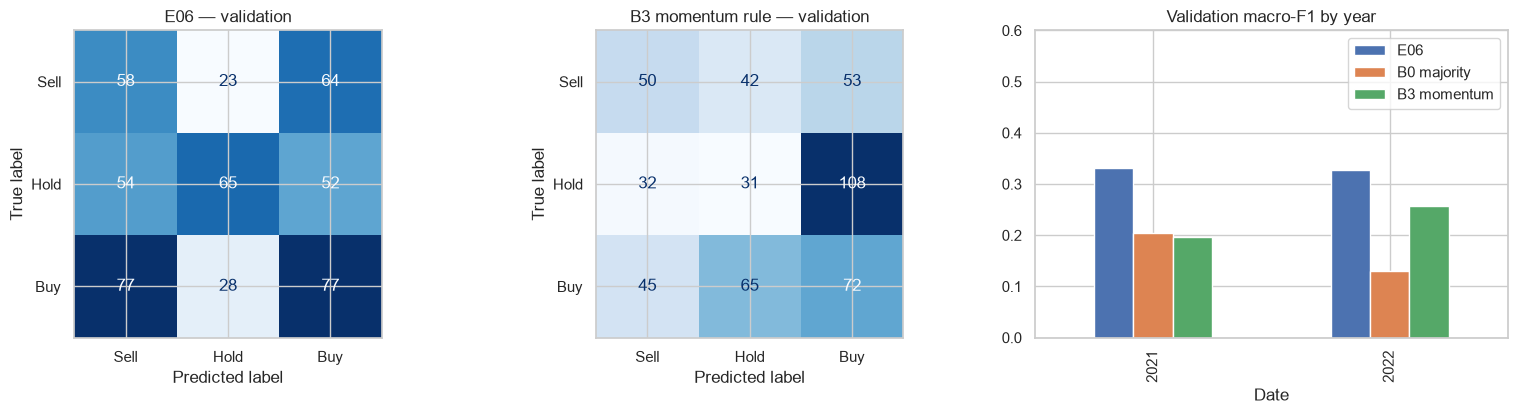

Predicted class share on validation: {'Buy': 0.388, 'Sell': 0.38, 'Hold': 0.233}


In [9]:
pred_va = best_est.predict(Xva[best_cols])
fig, ax = plt.subplots(1, 3, figsize=(16, 4.3))
plot_confusion(yva, pred_va, f"{BEST} — validation", ax=ax[0])
plot_confusion(yva, MODELS["E03"][0].predict(Xva), "B3 momentum rule — validation", ax=ax[1])
py = pd.DataFrame({BEST: per_year_macro_f1(yva, pred_va),
                   "B0 majority": per_year_macro_f1(yva, MODELS["E00"][0].predict(Xva)),
                   "B3 momentum": per_year_macro_f1(yva, MODELS["E03"][0].predict(Xva))})
py.plot(kind="bar", ax=ax[2]); ax[2].set_title("Validation macro-F1 by year"); ax[2].set_ylim(0, 0.6)
plt.tight_layout(); savefig("validation_confusion"); plt.show()
print("Predicted class share on validation:", pd.Series(pred_va).map(config.CLASS_NAMES).value_counts(normalize=True).round(3).to_dict())

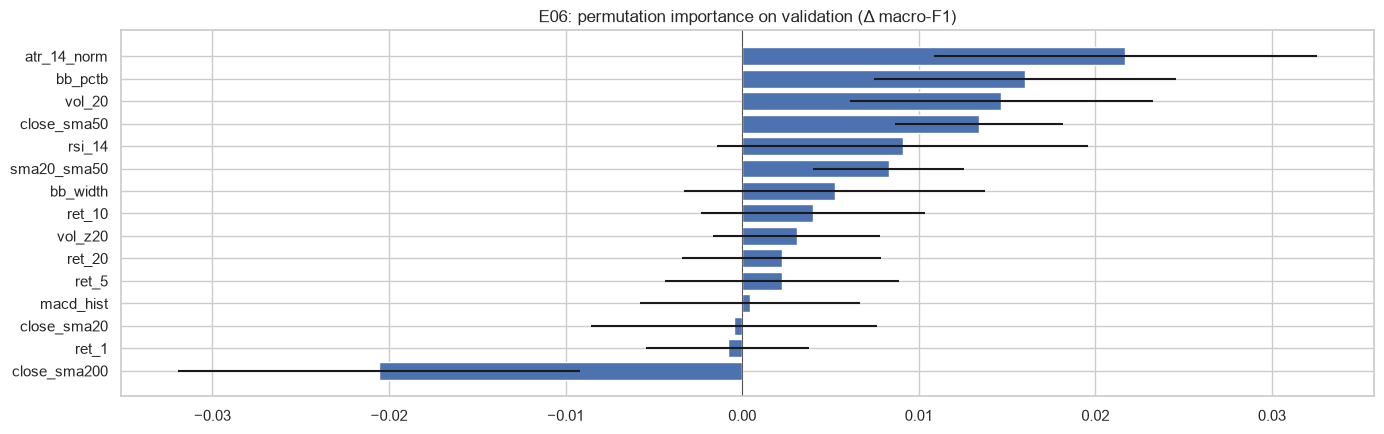

In [10]:
# Permutation importance on VALIDATION (association with the model's score, not causation)
pi = permutation_importance(best_est, Xva[best_cols], yva, scoring="f1_macro", n_repeats=30, random_state=config.SEED)
imp = pd.DataFrame({"mean": pi.importances_mean, "std": pi.importances_std}, index=best_cols).sort_values("mean")
fig, ax = plt.subplots(1, 2 if hasattr(best_est[-1], "coef_") else 1, figsize=(14, 4.5), squeeze=False)
ax[0, 0].barh(imp.index, imp["mean"], xerr=imp["std"]); ax[0, 0].axvline(0, color="k", lw=0.5)
ax[0, 0].set_title(f"{BEST}: permutation importance on validation (Δ macro-F1)")
if hasattr(best_est[-1], "coef_"):
    coef = pd.DataFrame(best_est[-1].coef_.T, index=best_cols, columns=[config.CLASS_NAMES[c] for c in best_est[-1].classes_])
    sns.heatmap(coef, annot=True, fmt=".2f", cmap="RdBu_r", center=0, ax=ax[0, 1], annot_kws={"size": 8})
    ax[0, 1].set_title("LR coefficients (standardised features)")
plt.tight_layout(); savefig("importance"); plt.show()

**Reading.**
- **Selected: E06 Random Forest** (balanced class weights, all 15 features, `min_samples_leaf=68`, `max_features="sqrt"`). Validation macro-F1 is 0.404 vs 0.333 for the best baseline (stratified random guess).
- The confusion matrix shows the signal is **Hold vs. "a big move"**, exactly as the EDA predicted. True Sells are predicted Sell 58× and Buy 64×; true Buys are predicted Sell 77× and Buy 77×. The model has **no ability to tell an up-move from a down-move**.
- Permutation importance (validation): volatility (`atr_14_norm`, `vol_20`) and position-in-range features (`bb_pctb`, `close_sma50`) help. **`close_sma200` has negative importance**: shuffling it *improves* the score. The long-trend relationship learned in 2010–2020 (mostly above the 200-day average) misleads the model in the 2022 bear market. This is regime shift in action. All of these are associations with the model's score, not causal effects.

## 8. Signal-rule selection on the validation backtest (Gate G3, part 2)
The selected model (trained on **Train only**) generates signals for every validation day. Candidate rules:
- `margin`: `None` = argmax class; `m` = Buy if P(Buy)−P(Sell) > m, Sell if P(Sell)−P(Buy) > m, else Hold;
- `min_hold`: minimum bars to keep a position before an exit is allowed.

Long-only, 0.1% fee + 0.05% slippage per side, fills at next open. Pre-stated rule: **highest after-cost Sharpe; ties → fewer trades.**

In [11]:
rows = []
for margin in [None, 0.0, 0.05, 0.1, 0.2]:
    for min_hold in [0, 5]:
        s = val_backtest(best_est, best_cols, margin=margin, min_hold=min_hold)
        rows.append({"margin": "argmax" if margin is None else margin, "min_hold": min_hold, **s})
rules = pd.DataFrame(rows).drop(columns="strategy")
from src.backtest import buy_and_hold
bh_val = summarize(buy_and_hold(prices.loc[val_days.index.min():val_days.index.max()]), "Buy & Hold")
display(rules.sort_values(["sharpe", "n_trades"], ascending=[False, True]))
print("Validation Buy & Hold:", {k: bh_val[k] for k in ["total_return", "sharpe", "max_drawdown"]})
best_rule = rules.sort_values(["sharpe", "n_trades"], ascending=[False, True]).iloc[0]
RULE = {"margin": None if best_rule["margin"] == "argmax" else float(best_rule["margin"]), "min_hold": int(best_rule["min_hold"])}
print("Selected signal rule:", RULE)

,margin,min_hold,total_return,cagr,ann_vol,sharpe,max_drawdown,calmar,n_orders,n_trades,exposure,total_fees,final_value
5,0.0500,5,-0.0019,-0.0010,0.1589,0.0730,-0.1725,-0.0060,26,13,0.5090,2727.7200,99808.9500
4,0.0500,0,-0.0181,-0.0091,0.1581,0.0210,-0.1704,-0.0530,28,14,0.4930,2883.7100,98193.8200
8,0.2000,0,0.0000,0.0000,0.0000,0.0000,0.0000,NaN,0,0,0.0000,0.0000,100000.0000
9,0.2000,5,0.0000,0.0000,0.0000,0.0000,0.0000,NaN,0,0,0.0000,0.0000,100000.0000
1,argmax,5,-0.0363,-0.0184,0.1624,-0.0330,-0.1898,-0.0970,53,27,0.5940,5597.4900,96368.7200
3,0.0000,5,-0.0415,-0.0210,0.1617,-0.0510,-0.1969,-0.1070,65,33,0.5430,6931.7700,95850.6400
0,argmax,0,-0.0390,-0.0197,0.1520,-0.0550,-0.1742,-0.1130,81,41,0.4890,8266.7200,96101.7900
2,0.0000,0,-0.0988,-0.0508,0.1500,-0.2730,-0.1774,-0.2860,97,49,0.4310,9498.9200,90117.4400
6,0.1000,0,-0.2072,-0.1098,0.1649,-0.6230,-0.2692,-0.4080,9,5,0.4830,785.0700,79284.2400
7,0.1000,5,-0.2072,-0.1098,0.1649,-0.6230,-0.2692,-0.4080,9,5,0.4830,785.0700,79284.2400


Validation Buy & Hold: {'total_return': 0.0477, 'sharpe': 0.217, 'max_drawdown': -0.245}
Selected signal rule: {'margin': 0.05, 'min_hold': 5}


**Reading.**
- On validation **no rule beats Buy & Hold** (Sharpe 0.22). The selected rule (`margin=0.05`, `min_hold=5`) has Sharpe 0.07 and a −0.2% return.
- **Costs dominate high-turnover rules.** Raw argmax trades 41 round trips in two years and pays ≈ USD 8.3k in fees and slippage (8% of capital). The minimum holding period cuts turnover by about half.
- `margin=0.2` never trades: the RF probabilities are compressed around 1/3, so the model is never that confident.
- The choice among 10 rules rests on two years of data with a few dozen trades, so this selection is **noisy**. §9 and `03_backtest` check whether it generalises.

## 8b. Freeze the configuration

In [12]:
best_params = {k: v for k, v in SEARCHES[BEST].best_params_.items()} if BEST in SEARCHES else {}
FROZEN = {
    "experiment": BEST, "model": RESULTS[BEST]["name"], "feature_cols": best_cols,
    "imbalance": RESULTS[BEST]["imbalance"],
    "pipeline_params": {k: (float(v) if isinstance(v, (np.floating, float)) else v) for k, v in best_params.items()},
    "signal_rule": RULE, "label": "±1% close→close, 5 trading days",
    "val_macro_f1": RESULTS[BEST]["macro_f1"], "frozen_before_test": True,
}
(config.OUTPUT_DIR / "frozen_config.json").write_text(json.dumps(FROZEN, indent=2, default=str))
# keep the train-only validation signals for the backtest notebook
proba_va = pd.DataFrame(best_est.predict_proba(val_days[best_cols]), index=val_days.index, columns=best_est.classes_)
proba_va.columns = [f"p_{config.CLASS_NAMES[c]}" for c in proba_va.columns]
proba_va["action"] = predict_actions(best_est, best_cols, margin=RULE["margin"])
proba_va.to_csv(config.OUTPUT_DIR / "val_predictions.csv")
FROZEN

{'experiment': 'E06',
 'model': 'RF',
 'feature_cols': ['ret_1',
  'ret_5',
  'ret_10',
  'ret_20',
  'close_sma20',
  'close_sma50',
  'close_sma200',
  'sma20_sma50',
  'rsi_14',
  'macd_hist',
  'bb_pctb',
  'bb_width',
  'vol_20',
  'atr_14_norm',
  'vol_z20'],
 'imbalance': 'class_weight=balanced',
 'pipeline_params': {'clf__max_depth': None,
  'clf__max_features': 'sqrt',
  'clf__min_samples_leaf': 68},
 'signal_rule': {'margin': 0.05, 'min_hold': 5},
 'label': '±1% close→close, 5 trading days',
 'val_macro_f1': 0.4036,
 'frozen_before_test': True}

## 9. Final evaluation on the sealed test set (Gate G4 — run once)
Only now is the test segment loaded. The frozen pipeline is refit on Train + Val (2010-01 → 2022-12, last 5 rows dropped) and evaluated on 2023–2024. Nothing below feeds back into any design decision.

In [13]:
tv = train_val_combined(ds)
X_tv, y_tv = tv[best_cols], tv["label"].astype(int)
final = clone(best_est).fit(X_tv, y_tv)
test = get_segments(ds, include_test=True)["test"]          # <- the ONLY place test labels are read
Xte, yte = test[best_cols], test["label"].astype(int)
print(f"refit on {len(tv)} rows {tv.index.min().date()}→{tv.index.max().date()}; test {len(test)} labelled rows {test.index.min().date()}→{test.index.max().date()}")

test_rows = {}
pred_te = final.predict(Xte)
test_rows[f"{BEST} (final)"] = classification_metrics(yte, pred_te, final.predict_proba(Xte))
for name, est in baselines().items():
    est.fit(tv[FEATURE_COLS], y_tv)
    p = est.predict(test[FEATURE_COLS])
    test_rows[name] = classification_metrics(yte, p, est.predict_proba(test[FEATURE_COLS]) if hasattr(est, "predict_proba") else None)
test_table = pd.DataFrame(test_rows).T
display(test_table[["n", "accuracy", "balanced_accuracy", "macro_f1", "f1_Sell", "f1_Hold", "f1_Buy", "log_loss"]])
print("Test class share:", yte.map(config.CLASS_NAMES).value_counts(normalize=True).round(3).to_dict())
print("Predicted share:", pd.Series(pred_te).map(config.CLASS_NAMES).value_counts(normalize=True).round(3).to_dict())

refit on 3267 rows 2010-01-04→2022-12-22; test 497 labelled rows 2023-01-03→2024-12-23


,n,accuracy,balanced_accuracy,macro_f1,f1_Sell,f1_Hold,f1_Buy,log_loss
E06 (final),497.0000,0.4487,0.4125,0.4080,0.2500,0.5904,0.3836,1.0576
B0_majority,497.0000,0.4165,0.3333,0.1960,0.0000,0.5881,0.0000,21.0315
B1_stratified,497.0000,0.3260,0.3091,0.3048,0.2056,0.4047,0.3042,24.2950
B2_always_buy,497.0000,0.3984,0.3333,0.1899,0.0000,0.0000,0.5698,NaN
B3_momentum_rule,497.0000,0.3521,0.2920,0.2380,0.0000,0.2264,0.4877,NaN


Test class share: {'Hold': 0.416, 'Buy': 0.398, 'Sell': 0.185}
Predicted share: {'Hold': 0.463, 'Buy': 0.336, 'Sell': 0.201}


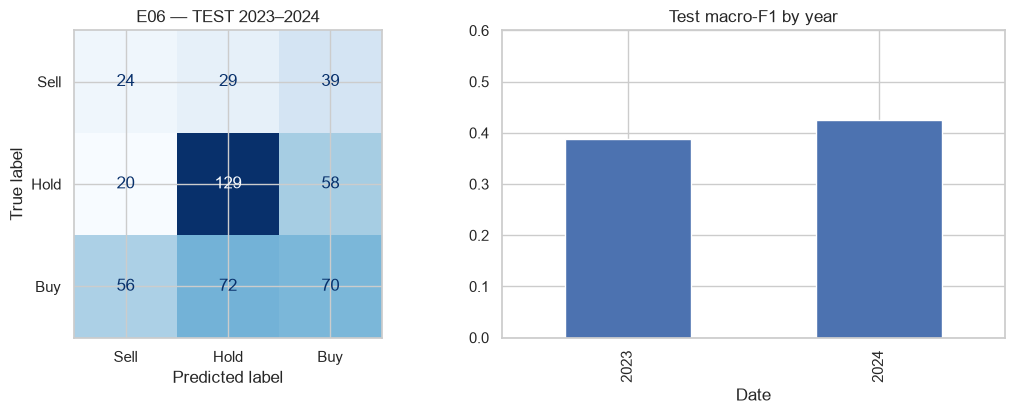

In [14]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4.3))
plot_confusion(yte, pred_te, f"{BEST} — TEST 2023–2024", ax=ax[0])
per_year_macro_f1(yte, pred_te).plot(kind="bar", ax=ax[1], title="Test macro-F1 by year"); ax[1].set_ylim(0, 0.6)
plt.tight_layout(); savefig("test_confusion"); plt.show()

In [15]:
# Persist: model, test metrics and signals for every test day (incl. the unlabelled last 5 days)
config.MODEL_DIR.mkdir(exist_ok=True)
joblib.dump(final, config.MODEL_DIR / "final_pipeline.joblib")
test_days = ds.loc[config.TEST[0]:config.TEST[1]]
proba_te = pd.DataFrame(final.predict_proba(test_days[best_cols]), index=test_days.index, columns=final.classes_)
action_te = apply_rule(proba_te, RULE["margin"])
proba_te.columns = [f"p_{config.CLASS_NAMES[c]}" for c in proba_te.columns]
proba_te["action"] = action_te
proba_te.to_csv(config.OUTPUT_DIR / "test_predictions.csv")
metrics = {"frozen_config": FROZEN,
           "validation": {k: RESULTS[k] for k in RESULTS},
           "test": {k: v for k, v in test_rows.items()},
           "test_per_year_macro_f1": per_year_macro_f1(yte, pred_te).round(4).to_dict()}
(config.OUTPUT_DIR / "metrics.json").write_text(json.dumps(metrics, indent=2, default=str))
print("saved:", "models/final_pipeline.joblib, outputs/metrics.json, outputs/test_predictions.csv")

saved: models/final_pipeline.joblib, outputs/metrics.json, outputs/test_predictions.csv


**Reading — final, one-time test result (2023–2024).**
- **Test macro-F1 0.408**, essentially equal to validation (0.404). The best baseline scores 0.305 (stratified random). Accuracy is 44.9% vs 41.7% for always predicting the majority class. This is in the "normal" range the brief describes, and the val→test consistency gives no hint of leakage.
- Per class: Hold F1 0.59 (recall 129/207), Buy 0.38, Sell 0.25. **Buy↔Sell confusion persists**: 39 of 92 true Sells were predicted Buy, and 56 of 198 true Buys were predicted Sell.
- Log loss is 1.058 vs ln 3 = 1.099 for a uniform guess. The probabilities are only marginally more informative than "no idea".
- This is a better-than-baseline *classifier* on a statistical metric. Whether that turns into money is a separate question → `03_backtest.ipynb`.